# Experiment 3: Multiple Linear Regression
**Aim:** Build a multiple linear regression model and evaluate it using MSE, RMSE and R².

**Dataset:** California Housing (`california_housing.csv`): 20640 rows, 8 features. Target = `MedHouseVal` (median house value in $100,000s).

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("california_housing.csv")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Shape: (20640, 9)
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
# correlation of each feature with the target
df.corr()["MedHouseVal"].sort_values(ascending=False)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64

In [5]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Train the model:  y = b0 + b1·x1 + b2·x2 + … + b8·x8

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Intercept (b0):", round(model.intercept_, 4))
pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_.round(4)})

Intercept (b0): 2.0719


,Feature,Coefficient
0,MedInc,0.8544
1,HouseAge,0.1225
2,AveRooms,-0.2944
3,AveBedrms,0.3393
4,Population,-0.0023
5,AveOccup,-0.0408
6,Latitude,-0.8969
7,Longitude,-0.8698


## Evaluate with MSE, RMSE and R²

In [7]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE  :", round(mse, 4))
print("RMSE :", round(rmse, 4))
print("R2   :", round(r2, 4))

MSE  : 0.5559
RMSE : 0.7456
R2   : 0.5758


In [8]:
pd.DataFrame({"Actual": y_test.values[:10], "Predicted": y_pred[:10].round(2)})

,Actual,Predicted
0,0.47700,0.72
1,0.45800,1.76
2,5.00001,2.71
3,2.18600,2.84
4,2.78000,2.60
5,1.58700,2.01
6,1.98200,2.65
7,1.57500,2.17
8,3.40000,2.74
9,4.46600,3.92


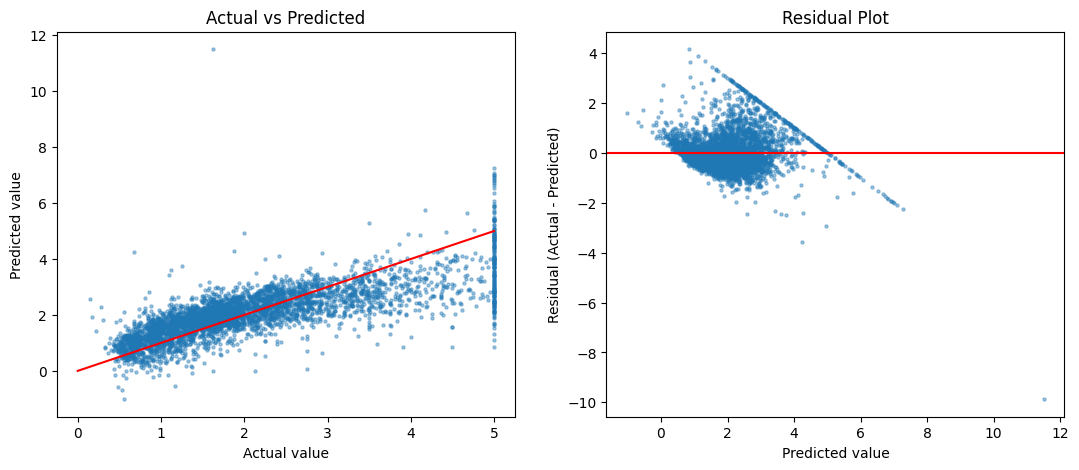

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(y_test, y_pred, s=5, alpha=0.4)
ax[0].plot([0, 5], [0, 5], color="red")          # perfect-prediction line
ax[0].set_xlabel("Actual value")
ax[0].set_ylabel("Predicted value")
ax[0].set_title("Actual vs Predicted")

residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals, s=5, alpha=0.4)
ax[1].axhline(0, color="red")
ax[1].set_xlabel("Predicted value")
ax[1].set_ylabel("Residual (Actual - Predicted)")
ax[1].set_title("Residual Plot")
plt.show()

## Conclusion
The model gives **R² ≈ 0.58**, so it explains about 58% of the variation in house prices. RMSE ≈ 0.75 means predictions are off by about $75,000 on average. `MedInc` (median income) has the strongest positive effect. The residual plot shows a pattern (the target is capped at 5.0), so a straight-line model cannot capture everything.